# A brief tutorial 

In [2]:
import time
from tqdm import tqdm
import numpy as np
import matplotlib.pyplot as plt

from pynav.agents import QAgent
from pynav.environment import Environment as Env
from pynav.simulators import Simulator as Sim


## Data Loading
Firstly, we load and pre-process the data

In [3]:
data = np.load("/storage/rando/data/nose_data_27_123.npy") # replace with your data path

n_thr = 3e-6 
data[data < n_thr] = 0.0


In [4]:
print(data.shape)

(2598, 27, 123)


We can visualize the data

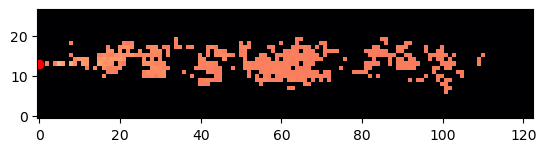

In [5]:
log_data = data.copy()
log_data[log_data == 0.0] = 1e-20

fig, ax = plt.subplots()
ax.imshow(np.log10(log_data[0, :, :]), cmap='magma', origin='lower', vmax=log_data.max())
ax.plot(0.0, 13.0, 'o', c='red')


Then, we create an environment specifing the data, the source position and the rewards

In [6]:
source_radius = 2
rewards = (1.0, 0.0)
source_position = np.array([14, 0])
seed = 12131415

env = Env(data = data, 
          source_position=source_position, 
          source_radius = source_radius, 
          rewards = rewards,
          seed=seed,
          )

Now, we load the plume information

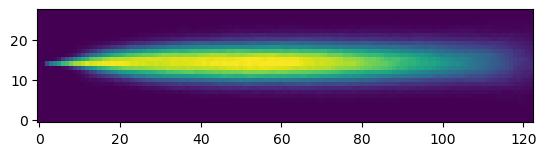

In [7]:
pmap = np.load("/home/arnaud/POMDP_PBVI_Exploration/Experiments/Olfactory Navigation/Data/statistics_nose_3e6_27_123.npy")


fig, ax = plt.subplots()
ax.imshow(pmap, origin='lower')

We can instantiate a q-learning agent using the `QAgent` class

In [8]:
eps_decay = 0.00005
alpha_decay = 0.0001
eps = lambda t : np.exp(-eps_decay * t)  #if np.exp(-eps_decay * t)  > 0.3 else 0.3
alpha = lambda t : np.exp(-alpha_decay * t)  if np.exp(-alpha_decay * t) > 0.001 else 0.001 #0.3 * np.exp(-alpha_decay * t) > 0.001 else 0.001

agent = QAgent(
    number_of_actions = 4,
    time_discretization_size = 400,
    memory_size = 10,
    adaptive_thr=-1.0,
    eps_greedy = eps,
    learning_rate = alpha,
    gamma = 1.0,
    s_thr = 3e-6
)

here we define a function to sample starting points inside the plume

In [9]:
rnd_state = np.random.RandomState(12131415)
start_points = (pmap > 0.0).astype(np.float64)
start_points /= np.sum(start_points)
start_points = start_points.ravel()
def sample_init_position():
    pos_idx = rnd_state.choice(range(start_points.shape[0]), 1, p=start_points)
    pos_y, pos_x = np.unravel_index(pos_idx, shape=pmap.shape)
    pos = np.concatenate([pos_y, pos_x])
    return pos

    

Now, to train the agent, we define the action space as a dictionary and we instantiate a Simulator (`Sim`)

In [10]:
actions = {
    0 : np.asarray([ 1, 0], dtype=np.int32), 
    1 : np.asarray([-1, 0], dtype=np.int32), 
    2 : np.asarray([0,  1], dtype=np.int32), 
    3 : np.asarray([0, -1], dtype=np.int32) 
}

action_labels = ['up', 'down', 'right', 'left']

trainer = Sim(env = env, actions = actions)

In [11]:
delta = 500
horizon = 400
num_episodes = 100000
seed = 12131415

_, average_crewards = trainer.train_agent(agent=agent, 
                    point_sampler=sample_init_position,
                    horizon=horizon,
                    num_episodes=num_episodes,
                    delta = delta,
                    seed = seed
                    )



  7%|▋         | 6902/100000 [02:39<41:59, 36.95it/s, avg R_t=0.032, eps=0.7082557653707635, alpha=0.501626229180926]  

In [102]:
H = 400 # horizon
num_episodes = 100000
cumulative_rewards = []
average_crewards = []
delta_size = 500
k = 0
iterator = tqdm(range(num_episodes))
for k in iterator:
    # Initialization
    agent.reset()
    pos = sample_init_position() 
    if pos[1] <= 2 or env.source_reached(pos):
        continue
    time_idx = rnd_state.randint(0, env.MAX_T)
    obs = env.get_observation(pos, time_idx)
    s = agent.update_state(obs) # update memory and compute olfactory state
    c_reward = 0.0
    for t in range(H):
        a = agent.select_action()
        pos, r, terminated = env.make_move(pos, actions[a])
        time_idx = (time_idx + 1) % env.MAX_T
        obs = env.get_observation(pos, time_idx)
        s_prime = agent.update_state(obs)
        c_reward += r * (agent.gamma**t) if t > 0 else r
        agent.update_q(s, a, s_prime, r)
        #print("\t[--] s = {}\ta = {}".format(s, a))
        if terminated:
            break
        s = s_prime
    agent.num_episodes += 1
    cumulative_rewards.append(c_reward)
    iterator.set_postfix({'avg R_t' : np.mean(cumulative_rewards[-delta_size:]), 
                          'eps' : f'{agent.eps_greedy(agent.num_episodes)}',
                          'alpha' : f'{agent.learning_rate(agent.num_episodes)}'})
    average_crewards.append(np.mean(cumulative_rewards[-delta_size:]))


100%|██████████| 100000/100000 [17:03<00:00, 97.75it/s, avg R_t=0.966, eps=0.006763938095788688, alpha=0.001]                


Text(0.5, 0, 'episodes')

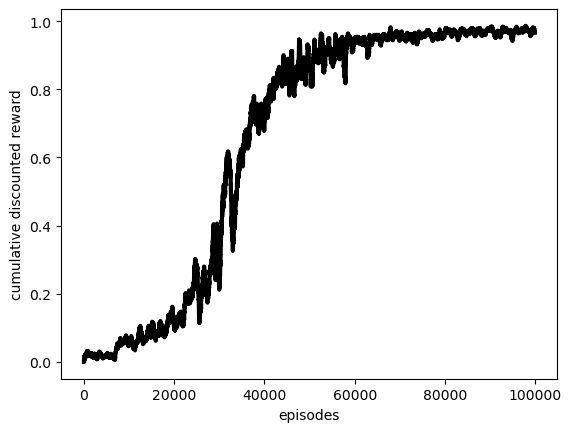

In [104]:
fig, ax = plt.subplots()
ax.plot(range(len(average_crewards)), average_crewards, '-', c='black', lw=3)

ax.set_ylabel("cumulative discounted reward")
ax.set_xlabel("episodes")


We can store the computed Q-table using `store_q` function

In [105]:
agent.store_q("./q_trained")

In [106]:
agent.reset()
init_pos = np.array([20, 100])
time_idx = 1#(time_idx + 1) % env.MAX_T
obs = env.get_observation(pos, time_idx)
s = agent.update_state(obs) # update memory and compute olfactory state
trace = []
source_pos = np.array([14.0, 0.0])
print(env.source_reached(np.array([14.0, 2.0])))
c_reward = 0.0
pos = init_pos.copy()
iterator = tqdm(range(H))
for t in iterator:
    a = agent.select_action()
    pos, r, terminated = env.make_move(pos, actions[a])
    obs = env.get_observation(pos, time_idx)
    time_idx = (time_idx + 1) % env.MAX_T
    s_prime = agent.update_state(obs)
    c_reward += r * (agent.gamma**t) if t > 0 else r
    trace.append((s, a, s_prime, r))
    if terminated:
        T_min = np.abs(source_pos[0] - init_pos[0]) + np.abs(source_pos[1] - init_pos[1]) - 2
        iterator.set_postfix({f"Source Reached! steps" : f"{t} steps", "T_min" : T_min, "T_min / T " : T_min / t})
        break
    s = s_prime


True


 33%|███▎      | 131/400 [00:00<00:00, 24053.49it/s, Source Reached! steps=131 steps, T_min=104, T_min / T =0.794]


Test agent for every test point at a given time slice

In [108]:
time_slice = 0
num_converged = 0
num_valid_pos = 0
T_ratio_lists = []

for time_slice in [0, 10, 100, 1000]:
    T_ratio = []
    T_ratio_valid = []
    iterator = tqdm(range(start_points.shape[0]))
    for pos_idx in iterator:
        pos_y, pos_x = np.unravel_index(np.array([pos_idx]), shape=pmap.shape)
        init_pos = np.concatenate([pos_y, pos_x])
        
        if init_pos[1] <= 2 or env.source_reached(init_pos):
            continue
        num_valid_pos += 1
        agent.reset()
        time_idx = time_slice
        obs = env.get_observation(pos, time_idx)
        s = agent.update_state(obs) # update memory and compute olfactory state
        trace = []
        source_pos = np.array([14.0, 0.0])
        c_reward = 0.0
        pos = init_pos.copy()
        #iterator = tqdm(range(H))
        for t in range(H):
            a = agent.select_action()
            pos, r, terminated = env.make_move(pos, actions[a])
            obs = env.get_observation(pos, time_idx)
            time_idx = (time_idx + 1) % env.MAX_T
            s_prime = agent.update_state(obs)
            c_reward += r * (agent.gamma**t) if t > 0 else r
            trace.append((s, a, s_prime, r))
            if terminated:
                T_min = np.abs(source_pos[0] - init_pos[0]) + np.abs(source_pos[1] - init_pos[1]) - 2
                iterator.set_postfix({'t':time_slice,f"Converged! steps" : f"{t} steps", "T_min / T " : T_min / (t + 1)})
                T_ratio.append(T_min / (t + 1))
                #print("[--] t_ratio = {}".format(T_ratio))
                num_converged +=1
                break
            s = s_prime
    T_ratio_lists.append(T_ratio)


100%|██████████| 3444/3444 [00:14<00:00, 237.94it/s, t=1000, Converged! steps=178 steps, T_min / T =0.743]


In [109]:
num_converged / num_valid_pos, np.mean(np.concatenate(T_ratio_lists))

(0.9473214285714285, 0.6665489639256771)

In [110]:

num_up, num_down = 0, 0
for i in range(agent.Q.shape[0]):
    print("[--] state = {}\taction = {}\tQ-values = {}".format(i, action_labels[np.argmax(agent.Q[i])], agent.Q[i] ))
    if action_labels[np.argmax(agent.Q[i])] == 'up':
        num_up += 1
    if action_labels[np.argmax(agent.Q[i])] == 'down':
        num_down += 1

[--] state = 0	action = left	Q-values = [79.201225 79.19584  79.19567  79.30592 ]
[--] state = 1	action = down	Q-values = [78.31743  78.881256 78.25881  78.307945]
[--] state = 2	action = down	Q-values = [78.225426 78.83991  78.21036  78.22654 ]
[--] state = 3	action = up	Q-values = [78.78511  78.1874   78.16377  78.184395]
[--] state = 4	action = up	Q-values = [78.77307  78.131065 78.133736 78.14068 ]
[--] state = 5	action = left	Q-values = [78.11913 78.07241 78.08772 78.75921]
[--] state = 6	action = up	Q-values = [78.7328  78.06545 78.02752 78.05523]
[--] state = 7	action = left	Q-values = [78.04151 77.99816 77.97716 78.69461]
[--] state = 8	action = up	Q-values = [78.66476 77.94012 77.89473 77.91831]
[--] state = 9	action = left	Q-values = [77.93042 77.87134 77.89013 78.60522]
[--] state = 10	action = up	Q-values = [78.570435 77.79056  77.792534 77.81546 ]
[--] state = 11	action = left	Q-values = [77.761604 77.75129  77.73469  78.50028 ]
[--] state = 12	action = left	Q-values = [77

In [111]:
num_up, num_down

(126, 102)

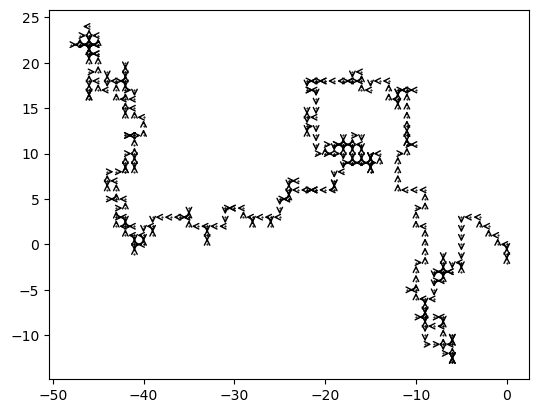

In [112]:
pos = np.array([0, 0])

path = [pos.copy()]
for i in range(1, agent.Q.shape[0]):
    pos += actions[np.argmax(agent.Q[i])]
#    print(actions[np.argmax(agent.Q[i])])
    path.append(pos.copy())

fig, ax = plt.subplots()
for i in range(len(path)-1):
    ax.plot(path[i][1], path[i][0], '.', c='black', ms=1)
    ax.annotate("", xytext=(path[i][1], path[i][0]), xy=(path[i+1][1], path[i+1][0]), arrowprops=dict(arrowstyle='->'))
#    print(action_labels[np.argmin(agent.Q[i])])
ax.set_aspect("equal")